<a href="https://colab.research.google.com/github/sonyxoxo/ipd/blob/main/%D1%81%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0_%D0%BC%D0%BE%D1%89%D0%BD%D0%BE%D1%81%D1%82%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Этап 5. Статистическая обработка мощности

Все расчёты используют один исходный файл из репозитория и общие функции. Нет повторных диалогов загрузки архивов. `NaN` не заменяется нулём, а у каждого результата сохраняется связь с конкретным исходным файлом.

## Имена переменных

- `source` — путь к исходному файлу; `measurements` — считанная **один раз** таблица `pandas`.
- `minutes` — полная минутная сетка, включая отсутствующие строки.
- `statistics_table` — описательная статистика поминутной активной мощности по месяцам.
- `hourly_table` — средняя мощность по каждому часу суток, рассчитанная по доступным минутам.
- `month_ids` — список выбранных для профилей месяцев; `profile_table` — характеристики 1440 минут суток.
- `mean_kw` и `median_kw` — соответственно среднее арифметическое и медиана мощности, кВт.
- `std_kw` — стандартное отклонение наблюдений с `ddof=0`, кВт.
- `q1_kw`, `q3_kw` — первый и третий квартили мощности, кВт.
- `iqr_kw` — межквартильный размах `q3_kw − q1_kw`, кВт.
- `observations` — число пригодных измерений, а не число всех минут месяца.
- `coverage_record_pct` — полнота периода наблюдений, %; `coverage_calendar_pct` — полнота календарного месяца, %.

Статистика неполного месяца описывает **только известные минуты**. Усреднение не доказывает, что пропуски случайны.

In [1]:
# Одна настройка пути к репозиторию. Исходные файлы не загружаются вручную.
from pathlib import Path
import subprocess
import sys

repo_dir = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ipd_analysis.py").is_file()), None)
if repo_dir is None:
    repo_dir = Path("/content/ipd")
    if not (repo_dir / "ipd_analysis.py").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/sonyxoxo/ipd.git", str(repo_dir)], check=True)
sys.path.insert(0, str(repo_dir))

from ipd_analysis import choose_source, load_measurements, regular_minutes, result_folder, save_csv, save_run_metadata

# Если в data/raw несколько файлов, задайте относительный путь явно:
# source = choose_source("data/raw/household_power_consumption.zip")
source = choose_source()
measurements = load_measurements(source)  # Один pd.read_csv на весь ноутбук.
output_dir = result_folder(source)
output_dir.mkdir(parents=True, exist_ok=True)
print("Источник:", source)
print("Строк:", len(measurements))

Источник: /content/ipd/data/raw/household_power_consumption.zip
Строк: 2075259


## Описательная статистика и почасовые профили

Среднее по часу рассчитывается по **всем известным минутам соответствующего часа**, а не как простое среднее из средних при разном числе наблюдений.

- `statistics_table` — одна строка на месяц со средним, медианой, минимумом, максимумом, стандартным отклонением и квартилями.
- `hourly_table` — по одной строке на час месяца, с `n_observed` и `n_expected` для проверки полноты.

In [2]:
from ipd_analysis import monthly_statistics, hourly_profiles, select_months, daily_profiles
from run_analysis import plot_hourly

minutes = regular_minutes(measurements)
month_ids = select_months(minutes)
statistics_table = monthly_statistics(minutes)
hourly_table = hourly_profiles(minutes, month_ids)
profile_table = daily_profiles(minutes, month_ids)
display(statistics_table.round(3))
display(hourly_table.head(8))
save_csv(statistics_table, output_dir / "05_monthly_statistics.csv")
save_csv(hourly_table, output_dir / "05_hourly_profiles.csv")
plot_hourly(hourly_table, output_dir / "05_hourly_profiles.png")
save_csv(profile_table, output_dir / "05_daily_profiles_quantiles.csv")

,month,observations,mean_kw,median_kw,min_kw,max_kw,std_kw,q1_kw,q3_kw,iqr_kw,coverage_record_pct,coverage_calendar_pct
0,2006-12,21992,1.901,1.708,0.194,9.132,1.418,0.496,2.692,2.196,99.982,49.265
1,2007-01,44638,1.546,1.376,0.198,9.272,1.292,0.378,2.318,1.940,99.996,99.996
2,2007-02,40318,1.401,1.266,0.204,9.410,1.312,0.320,2.140,1.820,99.995,99.995
3,2007-03,44639,1.319,0.852,0.200,10.670,1.276,0.314,1.868,1.554,99.998,99.998
4,2007-04,39477,0.891,0.384,0.104,8.160,0.989,0.272,1.354,1.082,91.382,91.382
5,2007-05,44640,0.986,0.462,0.106,7.672,1.006,0.290,1.408,1.118,100.000,100.000
6,2007-06,43157,0.827,0.356,0.082,7.614,0.953,0.224,1.284,1.060,99.900,99.900
7,2007-07,44509,0.667,0.292,0.098,7.240,0.823,0.204,0.972,0.768,99.707,99.707
8,2007-08,44618,0.764,0.278,0.098,8.694,0.897,0.190,1.250,1.060,99.951,99.951
9,2007-09,43198,0.969,0.386,0.098,8.110,1.066,0.218,1.440,1.222,99.995,99.995


,month,hour,mean_kw,n_observed,n_expected
0,2008-01,0,0.875571,1860,1860
1,2008-01,1,0.646414,1860,1860
2,2008-01,2,0.667765,1860,1860
3,2008-01,3,0.589171,1860,1860
4,2008-01,4,0.591811,1860,1860
5,2008-01,5,0.622119,1860,1860
6,2008-01,6,0.985363,1860,1860
7,2008-01,7,1.794883,1860,1860


PosixPath('/content/ipd/результаты/household_power_consumption-b916e64b/05_daily_profiles_quantiles.csv')

## Сглаживание суточного профиля

- `smoothed_table` — копия исходных средних профилей с новыми столбцами `smooth_15_kw` и `smooth_61_kw`.
- `smoothing_table` — таблица отличий между исходным и сглаженным профилями.
- `window_minutes` — ширина окна скользящего среднего: 15 или 61 минута.
- `mae_kw` — среднее абсолютное отличие двух профилей, кВт.
- `rmse_kw` — корень из среднего квадрата отличий, кВт.
- `peak_reduction_pct` — уменьшение максимума профиля после сглаживания, %.

Профиль продлевается циклически через полночь, потому что это **типичные сутки**, а не непрерывный исходный ряд. Около полуночи такая модель — допущение. Для неопределённых точек требуется не менее 80% известных соседних значений.

In [3]:
from ipd_analysis import smooth_profiles
from run_analysis import plot_smoothing

smoothed_table, smoothing_table = smooth_profiles(profile_table)
display(smoothing_table.round(4))
save_csv(smoothed_table, output_dir / "05_smoothed_profiles.csv")
save_csv(smoothing_table, output_dir / "05_smoothing_metrics.csv")
plot_smoothing(smoothed_table, output_dir / "05_smoothing.png")

,month,window_minutes,original_peak_kw,smoothed_peak_kw,peak_reduction_pct,mae_kw,rmse_kw
0,2008-01,15,3.1481,3.0228,3.9808,0.0388,0.0536
1,2008-01,61,3.1481,2.7909,11.3464,0.0787,0.1121
2,2008-04,15,2.3860,2.2860,4.1930,0.0397,0.0542
3,2008-04,61,2.3860,2.1223,11.0538,0.0730,0.0985
4,2008-07,15,2.0059,1.9136,4.6044,0.0417,0.0552
5,2008-07,61,2.0059,1.6606,17.2164,0.0673,0.0914
6,2008-09,15,2.3841,2.2271,6.5843,0.0409,0.0570
7,2008-09,61,2.3841,2.0871,12.4552,0.0806,0.1123


## Просмотр рисунка

- `smoothing_chart_path` — изображение результата сглаживания для всех выбранных месяцев. Оно хранится в каталоге результатов и отображается ниже.

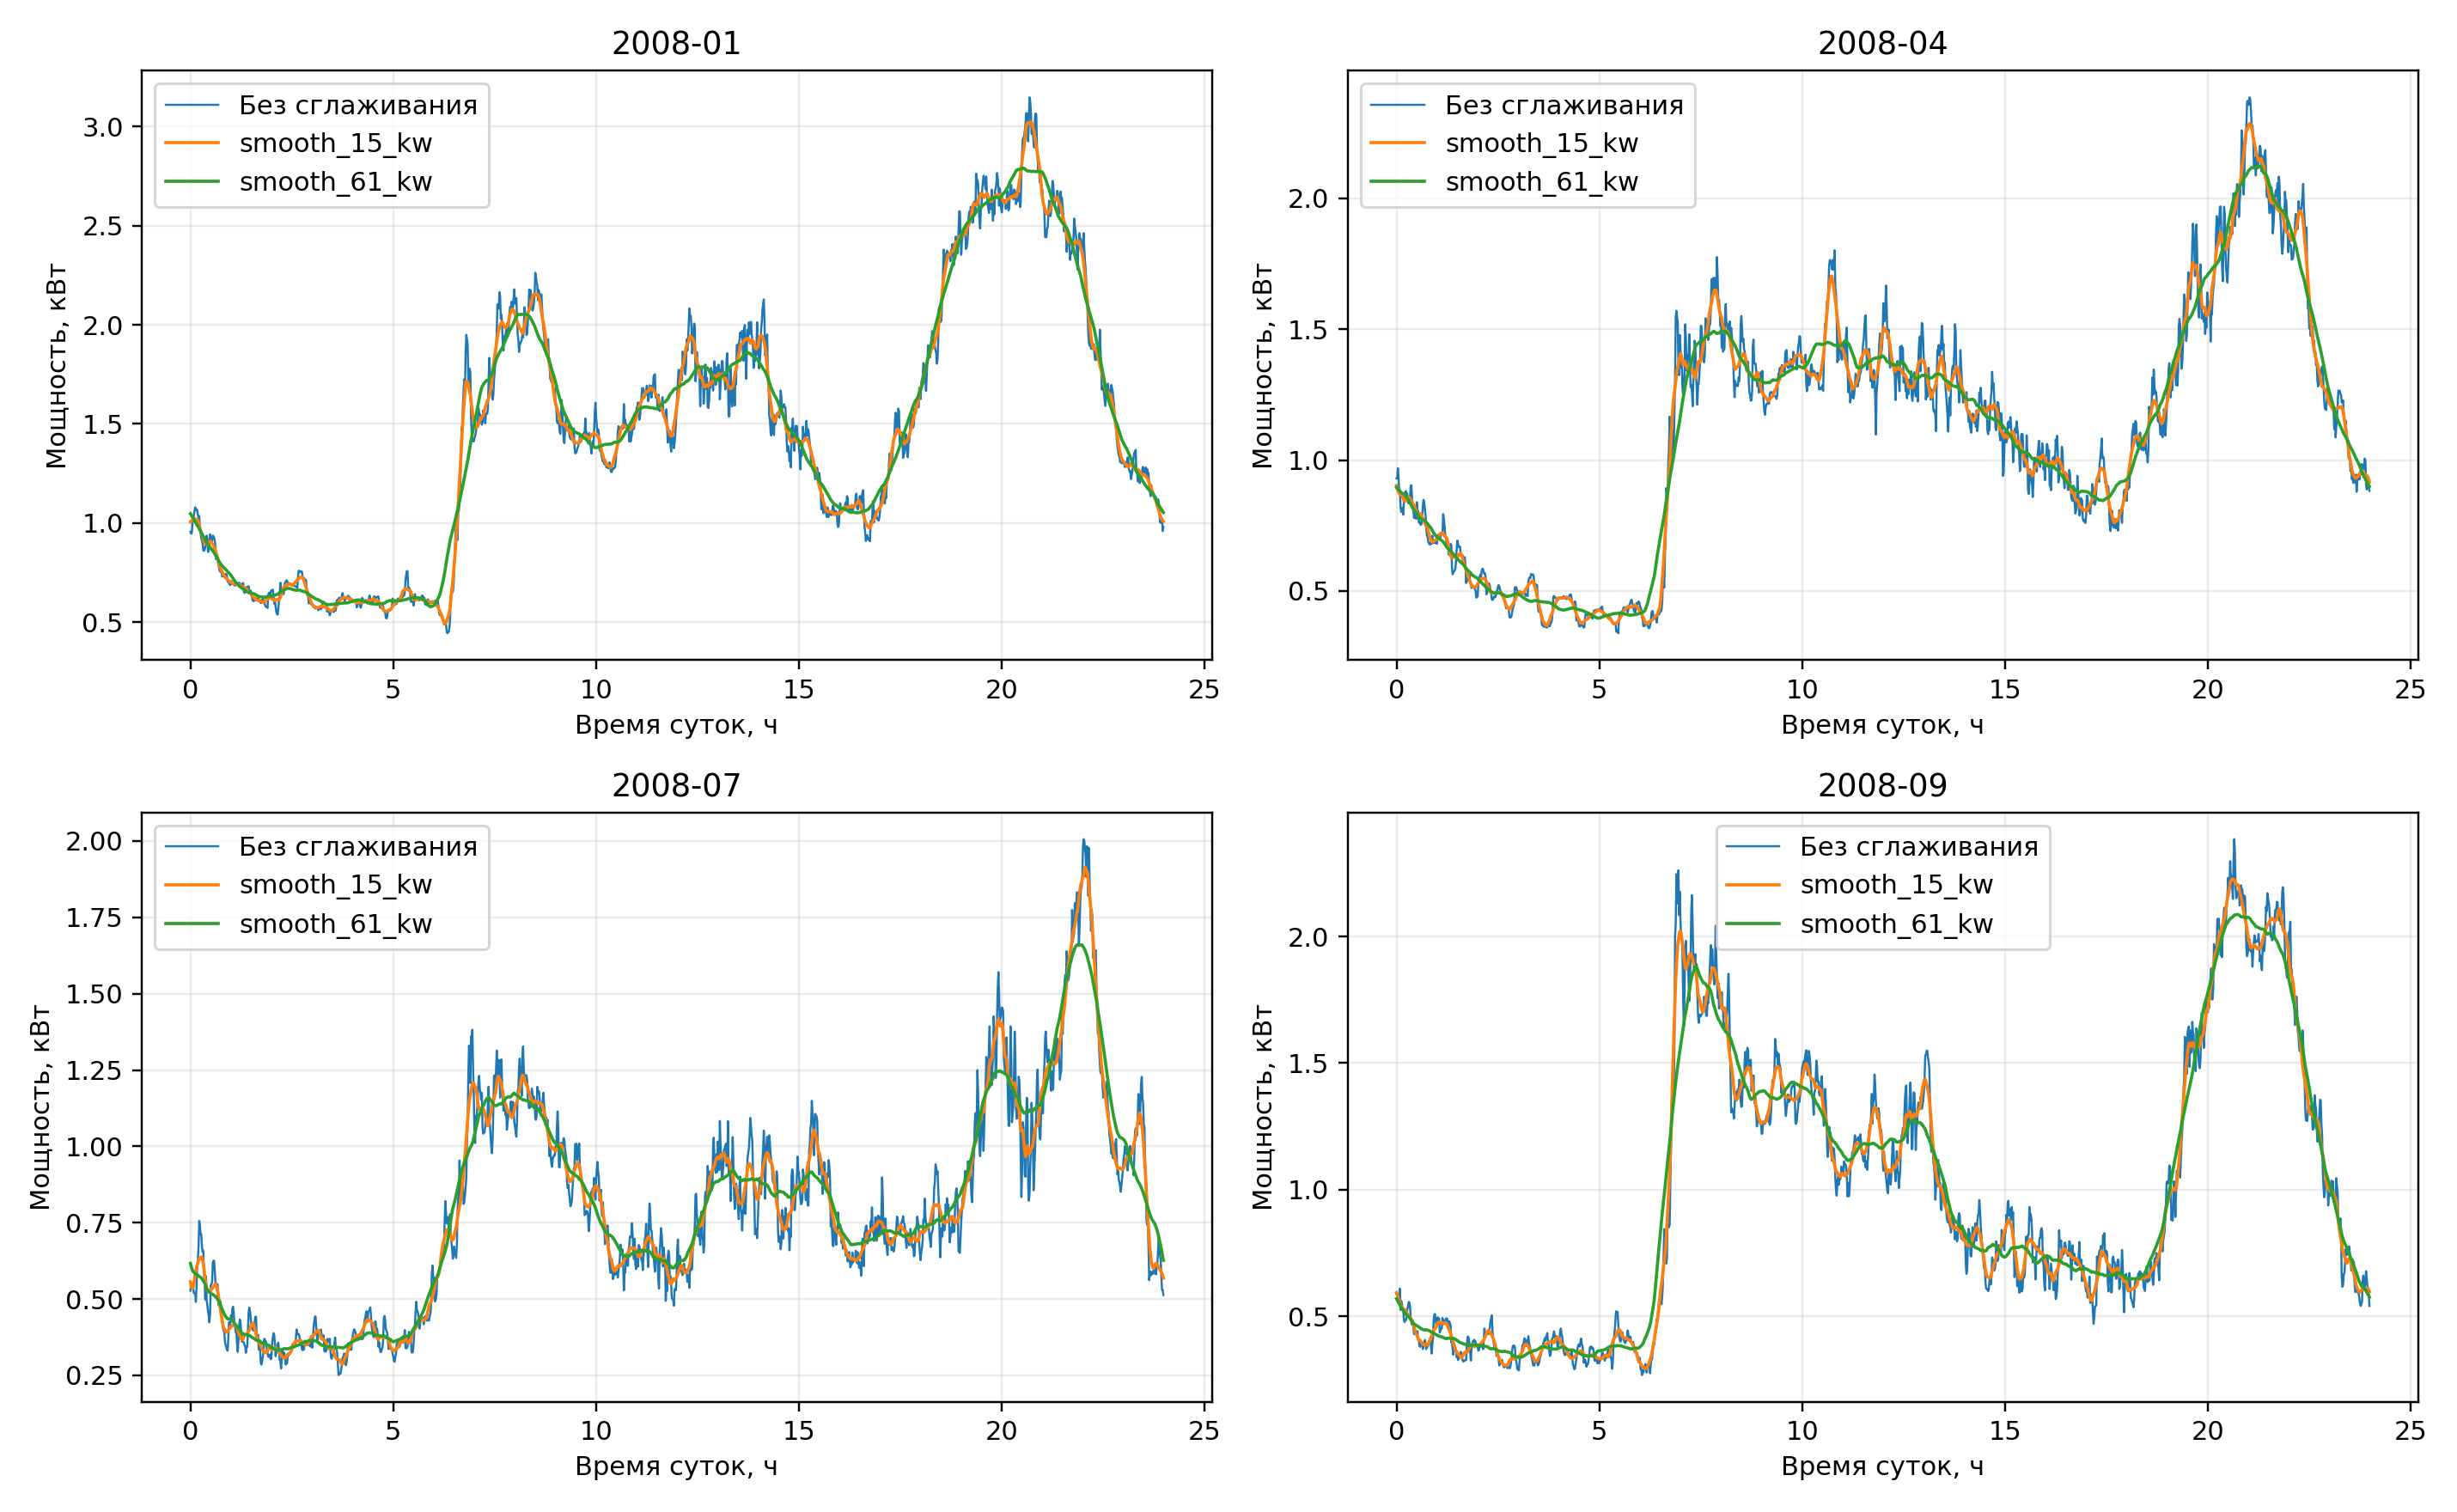

In [4]:
from IPython.display import Image, display

smoothing_chart_path = output_dir / "05_smoothing.png"
display(Image(filename=str(smoothing_chart_path)))

## Проверка влияния пропусков

- `experiment_profiles` — суточные профили при трёх вариантах: исходный месяц, случайные пропуски и непрерывный пропуск.
- `experiment_metrics` — сравнение сценариев, где `missing_count` — число удалённых измерений и `mae_kw` — отличие от исходного профиля.
- `incomplete_month_ids` — месяцы с отсутствующей или недопустимой мощностью.
- `complete_day_profiles` — сравнение профиля по всем известным измерениям с профилем только полных суток.
- `complete_day_metrics` — число полных суток и отличие между методами.

**Как читать рисунок:** верхняя панель показывает абсолютные суточные профили, нижняя — разность `P_с_пропусками − P_исходная` в кВт. Тонкая линия внизу — настоящие поминутные различия; толстая — только их скользящее среднее за 15 минут для наглядности. Показатель `MAE` рассчитывается по исходным различиям, без сглаживания.

Эксперимент проводится **только если есть целый календарный месяц без пропусков**. Если его нет, это честно сообщается, а не создаётся вымышленный «эталон». У новых файлов числа 43200, 8120 и 7226 не предполагаются.

Непрерывный пропуск начинается в ближайшие к середине месяца полночь; для сентября 2008 года это именно 15.09, как в исходном исследовании. `missing_start` и `missing_end` в таблице метрик фиксируют границы удалённого интервала.

In [5]:
from ipd_analysis import monthly_coverage, missing_experiment, compare_complete_days
from run_analysis import plot_missing_experiment, plot_complete_days

experiment_profiles, experiment_metrics = missing_experiment(minutes)
if experiment_metrics.empty:
    print("Эксперимент пропущен: нет полного календарного месяца без пропусков.")
else:
    display(experiment_metrics)
    save_csv(experiment_profiles, output_dir / "05_missing_experiment_profiles.csv")
    save_csv(experiment_metrics, output_dir / "05_missing_experiment_metrics.csv")
    plot_missing_experiment(experiment_profiles, output_dir / "05_missing_experiment.png")

incomplete_month_ids = monthly_coverage(minutes).loc[
    lambda table: table["missing_or_invalid"].gt(0), "month"
].tolist()
complete_day_profiles, complete_day_metrics = compare_complete_days(minutes, incomplete_month_ids)
if not complete_day_metrics.empty:
    display(complete_day_metrics)
    save_csv(complete_day_profiles, output_dir / "05_complete_day_profiles.csv")
    save_csv(complete_day_metrics, output_dir / "05_complete_day_metrics.csv")
    plot_complete_days(complete_day_profiles, output_dir / "05_complete_day_profiles.png")

,month,scenario,missing_count,mean_kw,mae_kw,missing_start,missing_end
0,2008-09,original,0,0.987680,0.000000,,
1,2008-09,random,4320,0.990760,0.034373,,
2,2008-09,continuous,4320,0.983256,0.029354,2008-09-15 00:00:00,2008-09-17 23:59:00


,month,complete_days,days_in_record,mean_all_kw,mean_complete_kw,mae_kw
0,2006-12,13,16,1.901295,1.928322,0.115154
1,2007-01,29,31,1.546034,1.506558,0.057489
2,2007-02,27,28,1.401084,1.366240,0.045082
3,2007-03,30,31,1.318627,1.285326,0.040639
4,2007-04,27,30,0.891189,0.893465,0.009800
5,2007-06,25,30,0.826814,0.826053,0.041102
6,2007-07,29,31,0.667367,0.656394,0.030640
7,2007-08,29,31,0.764186,0.751435,0.029070
8,2007-09,29,30,0.969318,0.959060,0.021678
9,2007-10,30,31,1.103911,1.095410,0.023384


## Проверка устойчивости вывода о влиянии пропусков

- `robustness_trials` — таблица отдельных опытов: 100 повторений случайных 10%-ных пропусков и все допустимые положения непрерывного пропуска с началом в полночь.
- `robustness_summary` — средняя ошибка `mean_mae_kw`, стандартное отклонение `std_mae_kw`, минимум, максимум и квантили 2,5%/97,5% по сценариям.
- `random_repetitions` — число повторов случайного опыта; принято 100, чтобы проверить устойчивость к конкретному расположению пропусков.

Эмпирические квантили описывают **разброс результатов проведённых сценариев**, а не доверительный интервал для всех возможных домохозяйств. Если месяц без пропусков отсутствует, сравнение не проводится.

In [6]:
from ipd_analysis import missing_experiment_robustness
from run_analysis import plot_missing_sensitivity

random_repetitions = 100
robustness_trials, robustness_summary = missing_experiment_robustness(
    minutes, random_repetitions=random_repetitions
)
if robustness_summary.empty:
    print("Невозможно оценить устойчивость: нет полного календарного месяца.")
else:
    display(robustness_summary.round(5))
    save_csv(robustness_trials, output_dir / "05_missing_robustness_trials.csv")
    save_csv(robustness_summary, output_dir / "05_missing_robustness_summary.csv")
    plot_missing_sensitivity(robustness_trials, output_dir / "05_missing_robustness.png")

,month,scenario,trials,mean_mae_kw,std_mae_kw,p025_mae_kw,p975_mae_kw,min_mae_kw,max_mae_kw
0,2008-09,continuous,28,0.03516,0.00367,0.03025,0.04296,0.02935,0.04413
1,2008-09,random,100,0.03384,0.00092,0.03225,0.03598,0.03171,0.03676


## Воспроизводимость результата

Последняя ячейка сохраняет `metadata.json` с SHA-256 исходного файла, хешами исполняемого кода, версиями библиотек и датой запуска. Поэтому любой результат можно связать с конкретным источником и версией обработки.

In [7]:
save_run_metadata(source, output_dir, {"notebook": 'статистика_мощности.ipynb'})

PosixPath('/content/ipd/результаты/household_power_consumption-b916e64b/metadata.json')